In [4]:
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

# Change the file names here only (the notebook is in notebooks/)
PATHS = {
    "all":   "../data/dataset.csv",
    "train": "../data/splits/train.csv",
    "val":   "../data/splits/val.csv",
    "test":  "../data/splits/test.csv",
}

def load(path):
    d = pd.read_csv(path).dropna(subset=["text"])
    d["text"] = d["text"].astype(str)
    d["n_words"] = d["text"].str.split().str.len()
    return d

df, train, val, test = (load(PATHS[k]) for k in ["all", "train", "val", "test"])

In [5]:
print("sizes:", {"all": len(df), "train": len(train), "val": len(val), "test": len(test)})
print("train + val + test =", len(train) + len(val) + len(test))

dist = pd.DataFrame({
    "train": train["label"].value_counts(normalize=True),
    "val":   val["label"].value_counts(normalize=True),
    "test":  test["label"].value_counts(normalize=True),
}).round(3)
print("\nclass share per split:\n", dist)

# exact text overlap between splits (should be 0)
for a, b, na, nb in [(train, val, "train", "val"), (train, test, "train", "test"), (val, test, "val", "test")]:
    print(f"exact overlap {na}/{nb}:", len(set(a["text"]) & set(b["text"])))

# near-duplicates: same first 120 characters (should be 0 or close)
pref = lambda d: set(d["text"].str[:120])
print("near-duplicate overlap train/test:", len(pref(train) & pref(test)))
print("near-duplicate overlap train/val:", len(pref(train) & pref(val)))

sizes: {'all': 1862, 'train': 1303, 'val': 279, 'test': 280}
train + val + test = 1862

class share per split:
                  train    val   test
label                               
Complaint        0.501  0.502  0.500
Contract         0.261  0.262  0.261
Service Request  0.238  0.237  0.239
exact overlap train/val: 0
exact overlap train/test: 0
exact overlap val/test: 0
near-duplicate overlap train/test: 0
near-duplicate overlap train/val: 0


In [6]:
print(train.groupby("label")["n_words"].describe().round(1))

                 count  mean   std   min   25%   50%   75%   max
label                                                           
Complaint        653.0  68.7   4.9  40.0  70.0  70.0  70.0  70.0
Contract         340.0  69.0   3.6  50.0  70.0  70.0  70.0  70.0
Service Request  310.0  61.9  10.2  40.0  53.0  69.0  70.0  70.0


In [8]:
print((train["n_words"] < 70).groupby(train["label"]).mean().round(3))

label
Complaint          0.093
Contract           0.118
Service Request    0.503
Name: n_words, dtype: float64


In [7]:
def caps_share(s):
    words = [w for w in s.split() if len(w) >= 3 and w.isalpha()]
    return sum(w.isupper() for w in words) / max(1, len(words))

texts = train["text"]
patterns = pd.DataFrame({
    "label": train["label"],
    "all-caps words %": texts.apply(caps_share) * 100,
    "has $": texts.str.contains(r"\$"),
    "has double quote": texts.str.contains('"'),
    "starts lowercase": texts.str.match(r"^[a-z]"),
    "starts with digit": texts.str.match(r"^\s*\d"),
    "space inside ( )": texts.str.contains(r"\(\s|\s\)"),
})
print(patterns.groupby("label").mean(numeric_only=True).round(3).T)

label              Complaint  Contract  Service Request
all-caps words %       2.229     6.411            0.273
has $                  0.366     0.041            0.000
has double quote       0.092     0.603            0.000
starts lowercase       0.032     0.171            0.158
starts with digit      0.003     0.435            0.000
space inside ( )       0.000     0.003            0.000


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

for lab, g in train.groupby("label"):
    vec = CountVectorizer(lowercase=True, stop_words="english", min_df=3)
    counts = vec.fit_transform(g["text"])
    freq = pd.Series(counts.sum(axis=0).A1, index=vec.get_feature_names_out())
    print("\n==", lab)
    print(freq.sort_values(ascending=False).head(20).to_string())


== Complaint
account        563
00             425
credit         327
complaint      255
bank           228
payment        204
loan           194
card           191
debt           163
mortgage       151
regarding      144
dispute        127
received       115
filing         108
information    108
payments       106
did            100
report          94
reporting       89
request         89

== Contract
agreement      355
shall          287
terms          154
services       138
term           132
section        120
company        116
definitions    114
party          109
means          107
following       92
set             82
forth           78
products        78
article         77
date            77
defined         71
business        63
parties         63
affiliate       62

== Service Request
issue         214
assistance    143
software      143
data          137
problem       125
appreciate    117
tools         112
provide        97
resolve        94
marketing      92
updates      

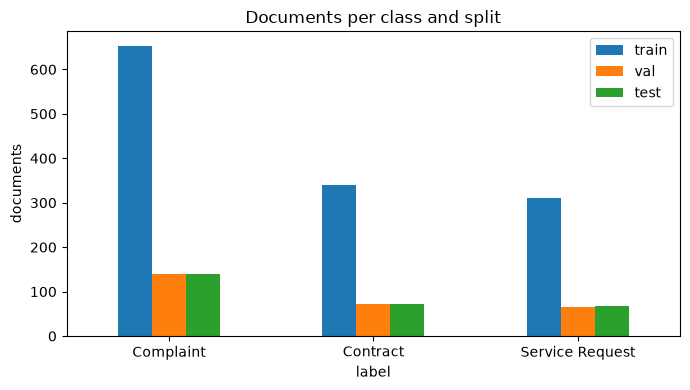

In [14]:
counts = pd.DataFrame({
    "train": train["label"].value_counts(),
    "val": val["label"].value_counts(),
    "test": test["label"].value_counts(),
})
ax = counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Documents per class and split")
ax.set_ylabel("documents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

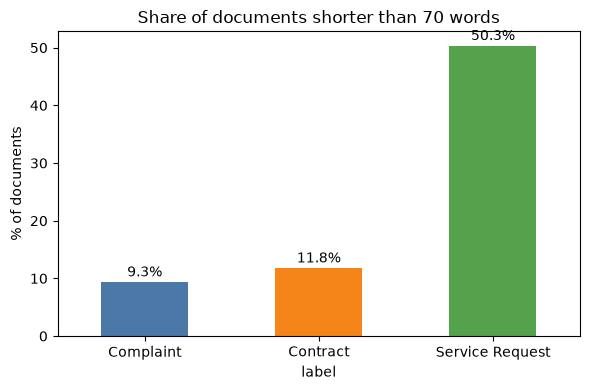

In [12]:
share_short = (train["n_words"] < 70).groupby(train["label"]).mean() * 100

ax = share_short.plot(kind="bar", figsize=(6, 4), color=["#4c78a8", "#f58518", "#54a24b"])
ax.set_title("Share of documents shorter than 70 words")
ax.set_ylabel("% of documents")
plt.xticks(rotation=0)
for i, v in enumerate(share_short):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.savefig("../reports/figures/length_short_share.png", dpi=150)
plt.show()

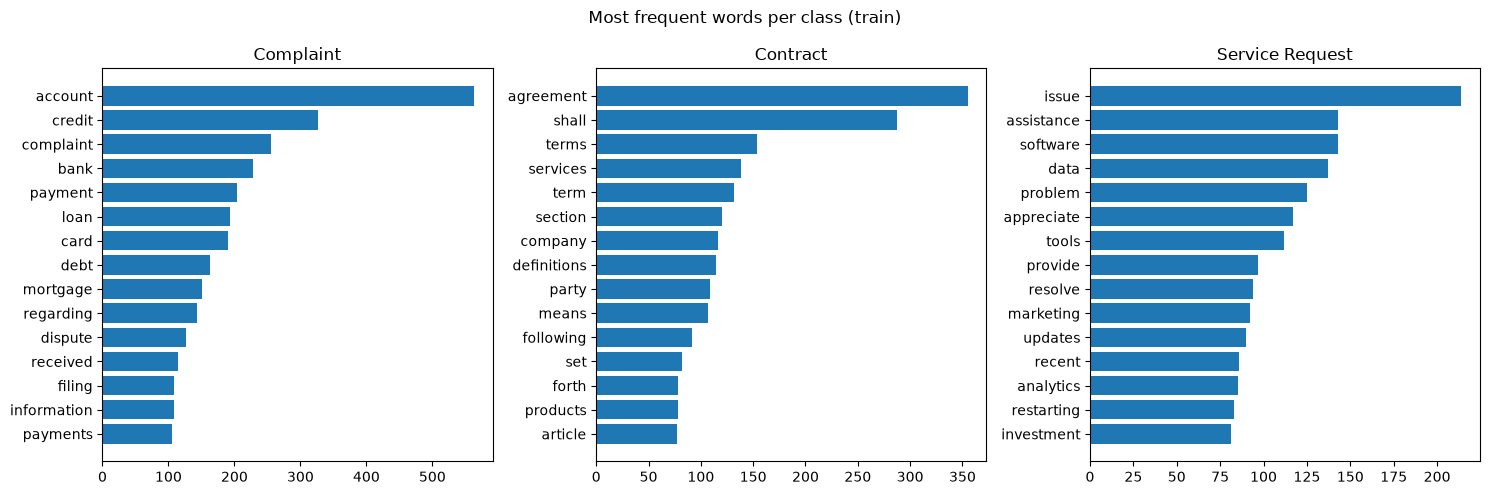

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (lab, g) in zip(axes, train.groupby("label")):
    vec = CountVectorizer(lowercase=True, stop_words="english", min_df=3,
                          token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
    counts = vec.fit_transform(g["text"])
    freq = pd.Series(counts.sum(axis=0).A1, index=vec.get_feature_names_out())
    top = freq.sort_values(ascending=False).head(15)[::-1]
    ax.barh(top.index, top.values)
    ax.set_title(lab)
plt.suptitle("Most frequent words per class (train)")
plt.tight_layout()
plt.savefig("../reports/figures/top_words.png", dpi=150)
plt.show()

## Findings

- **Split:** 1303 / 279 / 280 (70/15/15); class shares are identical across splits; no exact or near-duplicate overlap.
- **Length:** documents were truncated to 70 words. 50.3% of Service Requests are shorter than 70 words vs 9.3% (Complaint) and 11.8% (Contract), so a short text points to Service Request (possible shortcut).
- **Case:** Contracts have more ALL-CAPS words (6.4% vs 2.2% and 0.3%). Lowercasing is required in training and inference.
- **Numbers:** the token "00" is frequent in Complaints (from amounts such as $790.00). Replace numbers with a placeholder in the shared preprocessing.
- **Contract structure:** 43.5% start with a digit and 60.3% contain quotes (defined terms). Real contract structure, but incoming real contracts will have a title and preamble that we removed.
- **Service Request:** looks synthetic (words like "appreciate", "greatly", "assistance"; no dollar signs or quotes). It is easier to separate than real data.
- **Domain:** Complaints are US financial complaints, so vocabulary is finance-specific.
- **Expectation:** very high accuracy is likely and should not be read as real-world performance.

In [10]:
! pip install matplotlib


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
